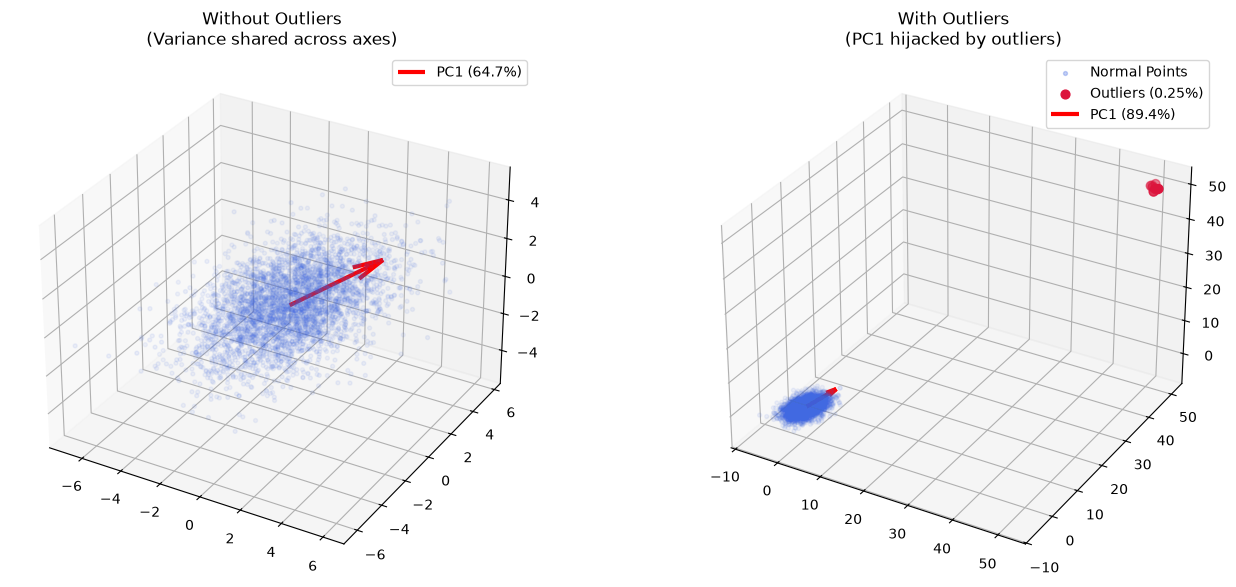

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

np.random.seed(42)

# 1. Normal 3D Data (4,000 points - spread across all 3 dimensions)
cov = [[3.0, 1.5, 0.8], 
       [1.5, 2.5, 1.0], 
       [0.8, 1.0, 2.0]]
X_clean = np.random.multivariate_normal([0, 0, 0], cov, size=4000)

# 2. Add extreme outliers (only 10 points = 0.25% of the data) far away
X_outliers = np.random.multivariate_normal([50, 50, 50], np.eye(3)*0.5, size=10)
X_corrupted = np.vstack([X_clean, X_outliers])

# 3. Fit PCA on both datasets
pca_clean = PCA().fit(X_clean)
pca_corrupted = PCA().fit(X_corrupted)

# 4. Plot 3D side-by-side
fig = plt.figure(figsize=(14, 6))

# Subplot 1: Clean Data
ax1 = fig.add_subplot(121, projection='3d')
ax1.scatter(X_clean[:, 0], X_clean[:, 1], X_clean[:, 2], c='royalblue', alpha=0.3, s=8)
c1 = pca_clean.mean_
v1_clean = pca_clean.components_[0] * np.sqrt(pca_clean.explained_variance_[0]) * 2
ax1.quiver(*c1, *v1_clean, color='red', lw=3, label=f'PC1 ({pca_clean.explained_variance_ratio_[0]*100:.1f}%)')
ax1.set_title("Without Outliers\n(Variance shared across axes)")
ax1.legend()

# Subplot 2: With Outliers
ax2 = fig.add_subplot(122, projection='3d')
ax2.scatter(X_clean[:, 0], X_clean[:, 1], X_clean[:, 2], c='royalblue', alpha=0.3, s=8, label='Normal Points')
ax2.scatter(X_outliers[:, 0], X_outliers[:, 1], X_outliers[:, 2], c='crimson', s=40, label='Outliers (0.25%)')
c2 = pca_corrupted.mean_
v1_corrupt = pca_corrupted.components_[0] * np.sqrt(pca_corrupted.explained_variance_[0]) * 1.5
ax2.quiver(*c2, *v1_corrupt, color='red', lw=3, label=f'PC1 ({pca_corrupted.explained_variance_ratio_[0]*100:.1f}%)')
ax2.set_title("With Outliers\n(PC1 hijacked by outliers)")
ax2.legend()

plt.tight_layout()
plt.show()